# LeetCode #48: Rotate Image

https://leetcode.com/problems/rotate-image/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n^2)$ | $O(n^2)$ |
| **Optimal: Transpose + Row Reverse ★** | $O(n^2)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force
Allocate a new $n \times n$ matrix and fill it using the rotation formula `result[j][n-1-i] = matrix[i][j]`. Correct but uses $O(n^2)$ extra space.

### Optimal: Transpose + Row Reverse ★
A 90° clockwise rotation decomposes into two in-place steps: (1) **transpose** — swap `matrix[i][j]` with `matrix[j][i]` for all $i < j$; (2) **reverse each row** — swap elements symmetrically within each row. Both steps are $O(n^2)$ time and $O(1)$ space.

**Why this is better than brute force:** Same Big-O time, but no extra $O(n^2)$ matrix allocation. All work is done in-place with a single swap variable.

**Constraints:**
* $n = \text{matrix.length} = \text{matrix}[i]\text{.length}$
* $1 \leq n \leq 20$
* Must rotate in-place with $O(1)$ extra space.


## Solutions

### C#

In [ ]:
public class Solution {
    public void Rotate(int[][] matrix) {
        int n = matrix.Length;
        // Step 1: Transpose — swap element at [i,j] with its mirror at [j,i]
        for (int i = 0; i < n; i++)
            for (int j = i + 1; j < n; j++)
                (matrix[i][j], matrix[j][i]) = (matrix[j][i], matrix[i][j]);

        // Step 2: Reverse each row to complete the 90° clockwise rotation
        for (int i = 0; i < n; i++) {
            int left = 0, right = n - 1;
            while (left < right) {
                (matrix[i][left], matrix[i][right]) = (matrix[i][right], matrix[i][left]);
                left++;
                right--;
            }
        }
    }
}

### Python

In [ ]:
class Solution:
    def rotate(self, matrix: list[list[int]]) -> None:
        n = len(matrix)
        # Step 1: Transpose — swap element at [i,j] with its mirror at [j,i]
        for i in range(n):
            for j in range(i + 1, n):
                matrix[i][j], matrix[j][i] = matrix[j][i], matrix[i][j]
        # Step 2: Reverse each row to complete the 90° clockwise rotation
        for row in matrix:
            row.reverse()

### Go

In [ ]:
func rotate(matrix [][]int) {
    n := len(matrix)
    // Step 1: Transpose — swap element at [i,j] with its mirror at [j,i]
    for i := 0; i < n; i++ {
        for j := i + 1; j < n; j++ {
            matrix[i][j], matrix[j][i] = matrix[j][i], matrix[i][j]
        }
    }
    // Step 2: Reverse each row to complete the 90° clockwise rotation
    for i := 0; i < n; i++ {
        left, right := 0, n-1
        for left < right {
            matrix[i][left], matrix[i][right] = matrix[i][right], matrix[i][left]
            left++
            right--
        }
    }
}

### Rust

In [ ]:
impl Solution {
    pub fn rotate(matrix: &mut Vec<Vec<i32>>) {
        let n = matrix.len();
        // Step 1: Transpose — swap element at [i,j] with its mirror at [j,i]
        for i in 0..n {
            for j in (i + 1)..n {
                let tmp = matrix[i][j];
                matrix[i][j] = matrix[j][i];
                matrix[j][i] = tmp;
            }
        }
        // Step 2: Reverse each row to complete the 90° clockwise rotation
        for row in matrix.iter_mut() {
            row.reverse();
        }
    }
}

## Example Scenarios

**1. Common Case**
**Input:** matrix = [[1,2,3],[4,5,6],[7,8,9]]
A 90° clockwise rotation maps $\text{matrix}[i][j] \to \text{matrix}[j][n-1-i]$. The four corners form one 4-cycle (1→3→9→7→1 positionally) while the center 5 is fixed. Result: $[[7,4,1],[8,5,2],[9,6,3]]$.

**2. Slightly Complex**
**Input:** matrix = 4×4 of 1..16
Even $n$ has no fixed center. Each concentric ring rotates as several independent 4-cycles — the outer ring holds three such cycles, the inner $2\times2$ holds one.

**3. Edge Case: Time**
**Input:** matrix = 5×5 of 1..25
There are $\lfloor n/2 \rfloor = 2$ rings and an odd center that maps to itself. Every cell is swapped exactly once, so the cost is $O(n^2)$ regardless of the values.

**4. Edge Case: Space**
**Input:** matrix = [[1,2],[3,4]]
The whole matrix is a single 4-cycle rotated with one temp variable — no second matrix is ever allocated, so auxiliary space is $O(1)$. Result: $[[3,1],[4,2]]$.

**5. Almost-Impossible but Plausible**
**Input:** matrix = [[42]]
A $1\times1$ matrix has $\lfloor n/2 \rfloor = 0$ rings, so the rotation loop never runs and the matrix is returned unchanged.


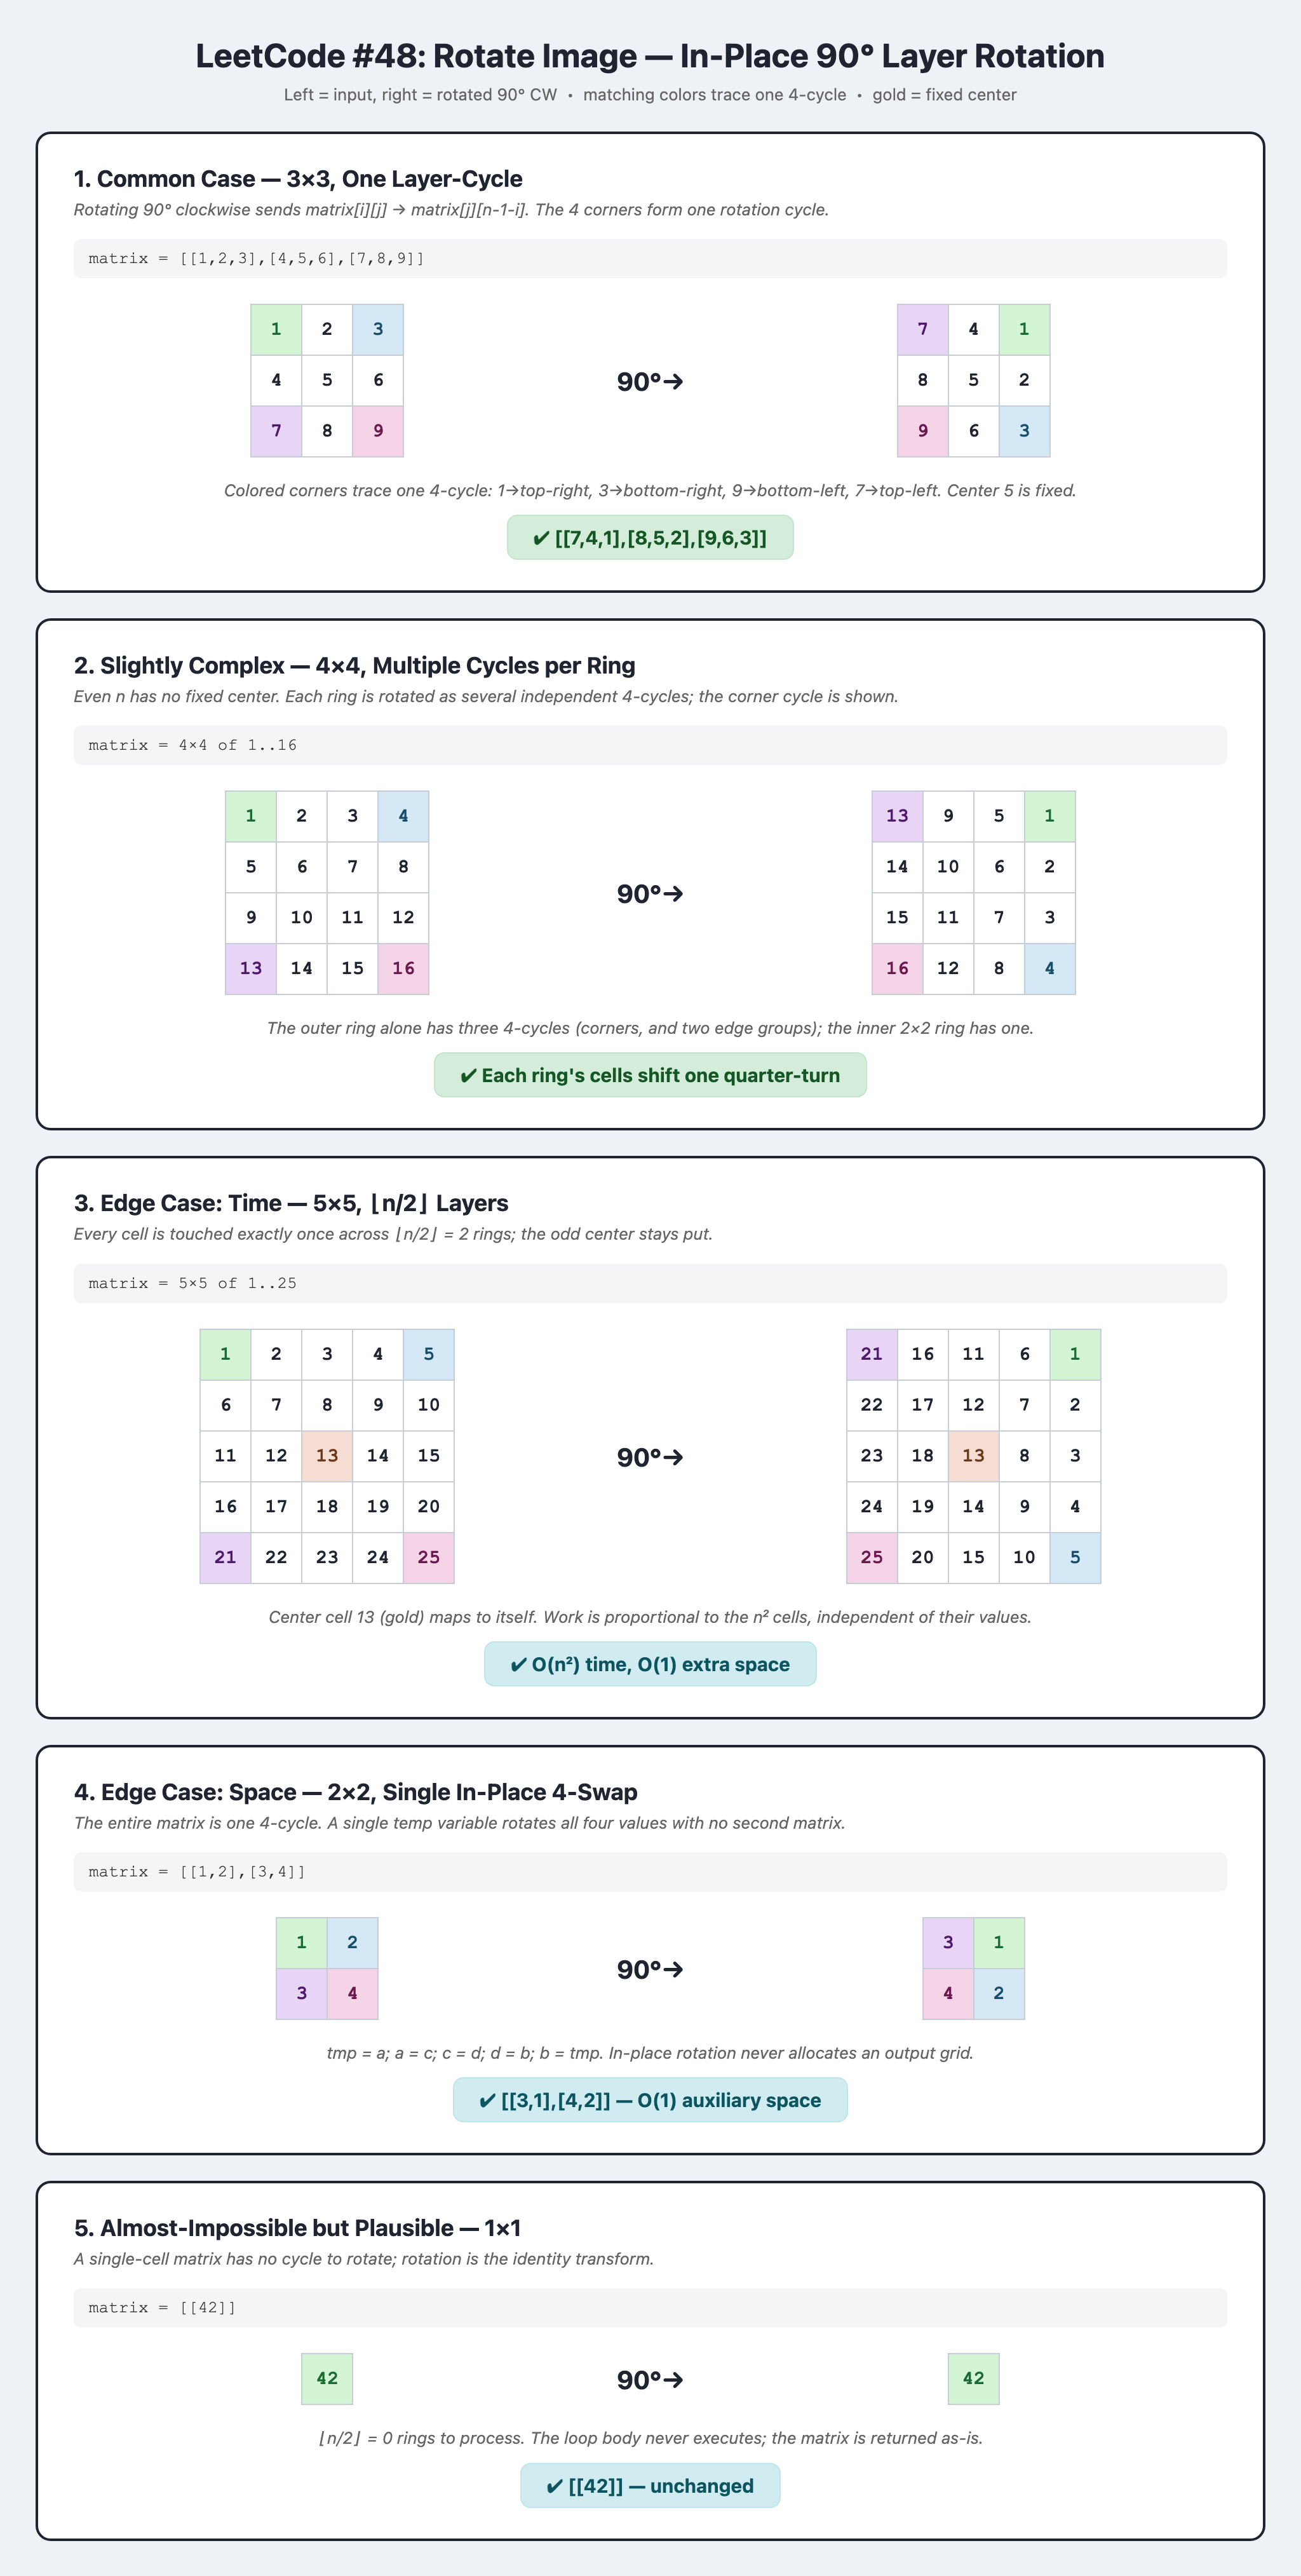